# Sales Prediction with Python

This project predicts sales from advertising spend on TV, Radio and Newspaper. It answers two questions:
- Which advertising channel is linked to the most sales?
- If a company changes its ad budget, how much could sales change?

**Dataset:** `data/Advertising.csv` (200 rows)
- **TV, Radio, Newspaper:** advertising spend per channel
- **Sales:** the value we want to predict

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the Data

The file has an extra `Unnamed: 0` column. It is only a row number, so I remove it.

In [2]:
df = pd.read_csv("data/Advertising.csv")

# remove the row-number column, it is not useful for prediction
df = df.drop(columns=["Unnamed: 0"])

print(df.shape)
df.head()

(200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 3. Check the Data

I checked the data before this step. It has no missing values and no duplicate rows, so no cleaning is needed here. The cell below confirms that.

In [3]:
print("Missing values:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


## 4. Explore the Relationships

Each chart shows one advertising channel against sales. A channel with points that rise together with sales is more useful for prediction.

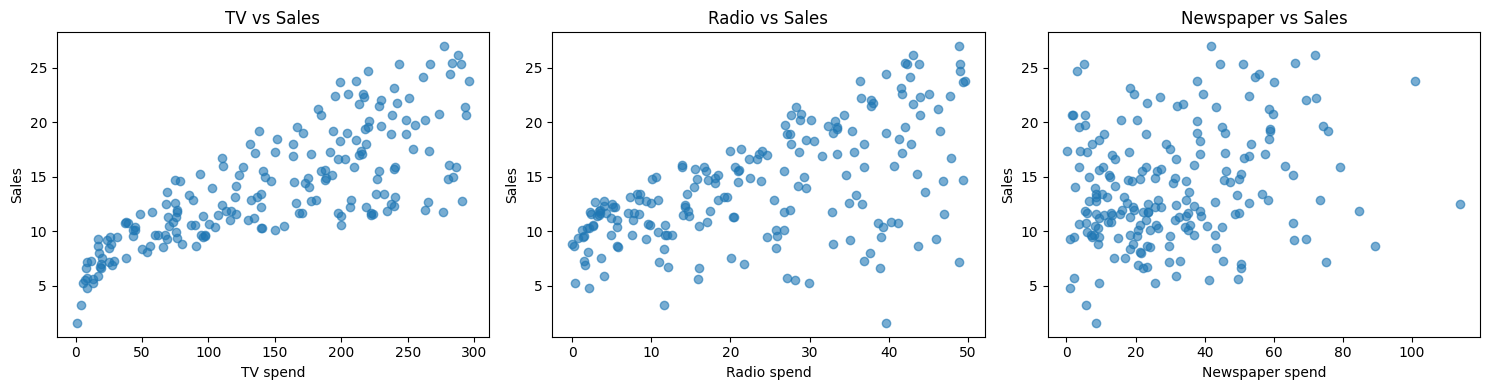

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    ax.scatter(df[col], df["Sales"], alpha=0.6)
    ax.set_xlabel(col + " spend")
    ax.set_ylabel("Sales")
    ax.set_title(col + " vs Sales")

plt.tight_layout()
plt.show()

## 5. Feature Selection

Correlation shows how closely each channel moves with sales. A value close to 1 is a strong positive link, and a value close to 0 is a weak one.

In [5]:
df.corr()["Sales"].sort_values(ascending=False)

Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64

TV and Radio have the strongest links to sales. Newspaper has the weakest link. I still keep all three features in the models, so the comparison shows whether Newspaper adds anything.

## 6. Split Into Inputs (X) and Answer (y)

- **X** is the advertising spend on each channel.
- **y** is the sales we want to predict.

In [6]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

## 7. Split Into Training and Testing Data

The models learn from 80% of the rows and are tested on the other 20%, which they have never seen.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 160
Testing rows: 40


## 8. Train the Models

- **Linear Regression** is the simple baseline. It assumes each channel adds a fixed amount to sales.
- **Random Forest** combines many decision trees and can capture more complex patterns.

In [8]:
# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Model 2: Random Forest
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

## 9. Compare the Results

**What the numbers mean:**
- **MAE:** the average size of a prediction error. Lower is better.
- **RMSE:** like MAE, but big errors count more. Lower is better.
- **R2:** how much of the change in sales the model explains. Closer to 1 is better.

In [9]:
def get_scores(name, pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    }

results = pd.DataFrame([
    get_scores("Linear Regression", lr_pred),
    get_scores("Random Forest", rf_pred),
])

results

,Model,MAE,RMSE,R2
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.628925,0.757657,0.981813


## 10. Plot Actual vs Predicted Sales

Each dot is one test row. Dots close to the red line mean good predictions.

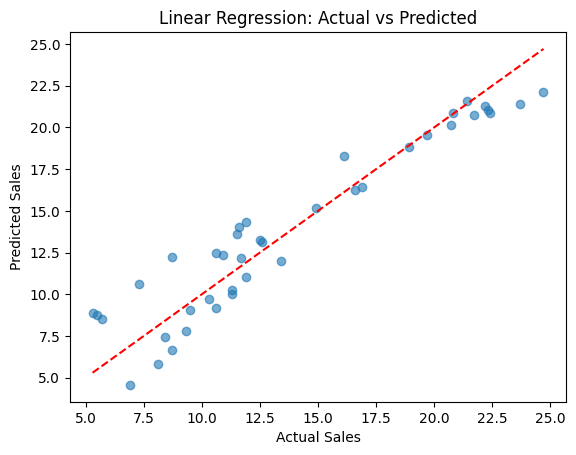

In [10]:
plt.scatter(y_test, lr_pred, alpha=0.6)

# red line = perfect prediction
low = y_test.min()
high = y_test.max()
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

## 11. How Much Does Each Channel Matter?

The Linear Regression coefficient tells us how much sales change when that channel's spend goes up by one unit, while the other channels stay the same. A bigger number means a stronger effect.

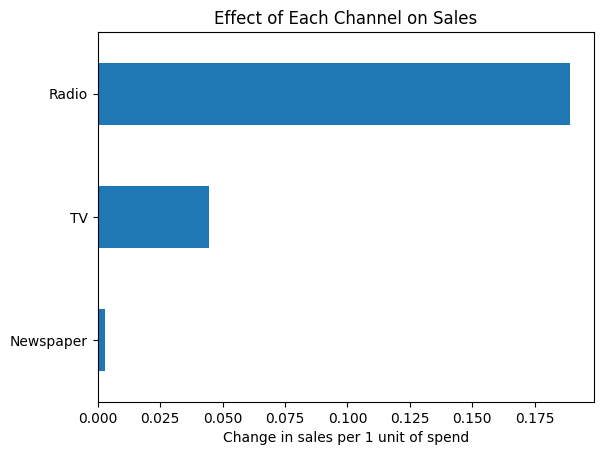

Newspaper    0.002761
TV           0.044730
Radio        0.189195
dtype: float64

In [11]:
coefficients = pd.Series(lr.coef_, index=X.columns).sort_values()

coefficients.plot(kind="barh")
plt.title("Effect of Each Channel on Sales")
plt.xlabel("Change in sales per 1 unit of spend")
plt.show()

coefficients

## Conclusion

Random Forest performed better than Linear Regression. It had an R2 of 0.98 compared to 0.90, and a lower MAE of 0.63 compared to 1.46. Radio had the biggest effect per unit of spend in the Linear Regression model, at about 0.19 more sales per unit, compared with about 0.04 for TV and almost nothing for Newspaper. Even though TV had the strongest link to sales in the correlation check, a company with a fixed budget should compare each channel's cost per unit before moving money from TV to Radio, because TV budgets are much larger. Newspaper added very little, so it is the first channel I would cut or test again.